<center>

# 🎮 **Player Segmentation Analysis**

### Feature Engineering and Data Preparation

---

**Author:** Nelson Nicolás Hernández Becerra  
**Project Type:** Product Analytics & Customer Segmentation  
**Tech Stack:** Python, Pandas, Scikit-Learn, Matplotlib, Seaborn

</center>

# 📖 **Notebook Overview**

After completing the data quality assessment and exploratory analysis, the next stage focuses on transforming the raw information into a structured analytical dataset suitable for segmentation.

Feature engineering plays a critical role in the success of clustering projects, as it allows the creation of meaningful variables that better represent player behavior, engagement, monetization, and social activity.

The objective of this notebook is to prepare the dataset for machine learning by creating new features, selecting the final segmentation variables, and standardizing them prior to segmentation.

# <font color='green'>📊 **Step 4. Feature Engineering**</font>

In this stage, we create and transform variables that may better capture the behavioral characteristics of players.

Rather than relying exclusively on the original features, we aim to build more informative representations of progression, engagement, social interaction, and monetization patterns.

These engineered features will serve as the foundation for the clustering process developed in the next notebook.

## <font color='green'>🟢 **4.1 Dataset Loading and Preparation**</font>

Before creating new features, we load the dataset and review its structure to ensure that all variables are available for processing.

This step establishes the foundation for the feature engineering workflow and guarantees that the notebook can be executed independently from previous stages.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)

sns.set_style("whitegrid")

DATASET_PATH = Path("../data/raw/dataset.csv")

df = pd.read_csv(DATASET_PATH)

print("✅ Dataset loaded successfully.")

✅ Dataset loaded successfully.


### <font color='green'>**4.1.1 Unit of Analysis**</font>

As established in the data quality assessment (notebook 2, section 2.3.3), each row of the dataset is treated as an independent player record, since `Player ID` is not a reliable player-level key. Counts and chart labels in this notebook therefore refer to **records**, and the word "players" is used as shorthand for player records.

## <font color='green'>🟢 **4.2 Monetization Features**</font>

In this section, we create new features related to player spending behavior.

Monetization is a critical business dimension in digital products and games, as it helps distinguish between players who generate revenue and those who interact with the game without making purchases.

The first feature focuses on identifying whether a player has completed at least one purchase.

**Note on terminology**. Each record contains a single Purchase Amount and a single Purchase Date. Throughout this project, “spending” refers to the recorded purchase amount of a record, and “revenue” to the sum of those amounts. The currency is not documented in the dataset, and the data does not allow us to determine whether the amount represents a single transaction or accumulated spending.

### <font color='green'>**4.2.1 Is Payer Feature**</font>

We create a binary feature that indicates whether a player has made at least one in-app purchase.

Players with a purchase amount greater than zero are classified as payers (`1`), while all remaining players are classified as non-payers (`0`).

This feature will be useful for future monetization analysis and may play an important role in the interpretation of player segments.

In [2]:
df["is_payer"] = np.where(
    df["Purchase Amount"].fillna(0) > 0,
    1,
    0
)

df["is_payer"].value_counts()

is_payer
1    1244
0     756
Name: count, dtype: int64

The newly created `is_payer` feature identifies **1,244 paying records** and **756 non-paying records**.

This distribution confirms that a majority of players in the dataset have generated revenue through in-app purchases, while a substantial segment remains non-paying.

From a business perspective, this feature provides a simple yet powerful distinction between monetized and non-monetized users and may become particularly useful when interpreting player segments later in the project.

Additionally, the results are consistent with the missing value analysis conducted in the previous notebook, where many missing purchase-related records appeared to correspond to non-paying players.

### <font color='green'>**4.2.2 Is Payer Distribution**</font>

To better understand the monetization structure of the player base, we visualize the distribution of paying and non-paying players.

This provides a quick overview of the relative size of each monetization group within the dataset.

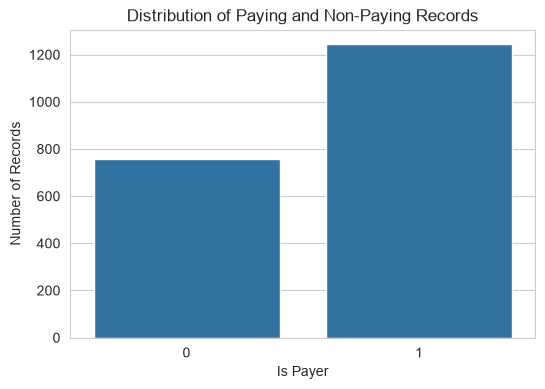

In [3]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="is_payer"
)

plt.title("Distribution of Paying and Non-Paying Records")
plt.xlabel("Is Payer")
plt.ylabel("Number of Records")

plt.show()

The distribution shows that paying players represent the majority of the dataset, accounting for a larger share of observations than non-paying players.

This result reinforces the relevance of monetization as a key behavioral dimension and suggests that spending behavior may play an important role in distinguishing player segments.

The `is_payer` feature provides a simple and interpretable monetization indicator that can support both exploratory analysis and cluster interpretation in later stages of the project.

### <font color='green'>**4.2.3 Monetization Missing Value Treatment**</font>

To prepare the monetization features for clustering, missing values in `Purchase Amount` are replaced with zero.

Based on the previous data quality assessment, these missing values are interpreted as non-paying players rather than missing observations. This also applies to the 10 records with a purchase date but no amount, whose spending is unknown and which are retained as non-payers (see notebook 2, section 2.1.6).

Using zero preserves the business meaning of the feature while ensuring compatibility with machine learning algorithms.

In [4]:
df["Purchase Amount"] = (
    df["Purchase Amount"]
    .fillna(0)
)

## <font color='green'>🟢 **4.3 Social Features**</font>

In this section, we create features that capture the social behavior of players.

Social interaction is often associated with engagement, retention, and community participation in gaming environments. By combining multiple social indicators into a single feature, we aim to create a more informative representation of player social activity.

### <font color='green'>**4.3.1 Social Score**</font>

We create a social engagement score by combining key social interaction variables available in the dataset.

The feature is designed to summarize a player's overall level of social participation by incorporating:

- Friend Invites Sent
- Friend Invites Received
- Guild Chat Messages

For this initial version, the score is calculated as the sum of these three components.

More sophisticated weighting strategies could be explored in future iterations of the project, but a simple and interpretable approach is preferred at this stage.

In [5]:
df["social_score"] = (
    df["Friend Invites Sent"]
    + df["Friend Invites Received"]
    + df["Guild Chat Messages"]
)

df["social_score"].describe()

count    2000.000000
mean       53.481000
std        44.748619
min         0.000000
25%        22.000000
50%        41.000000
75%        72.000000
max       292.000000
Name: social_score, dtype: float64

The newly created `social_score` feature exhibits substantial variability across the player base, ranging from players with no social activity to highly interactive users.

The median score of **41** indicates that half of the players accumulate fewer than 41 social interactions, while the upper quartile reaches **72**, suggesting the presence of a group with significantly higher levels of social participation.

The maximum value of **292** further supports the existence of highly social players who may represent a distinct behavioral segment within the dataset.

Overall, the feature successfully consolidates multiple social interaction metrics into a single, interpretable measure that may contribute to the identification of socially engaged player profiles during clustering.

### <font color='green'>**4.3.2 Social Score Distribution**</font>

To better understand the behavior of the newly engineered feature, we examine its distribution across players.

This visualization helps assess the variability of social participation within the player base and evaluate whether the feature captures meaningful differences in social engagement.

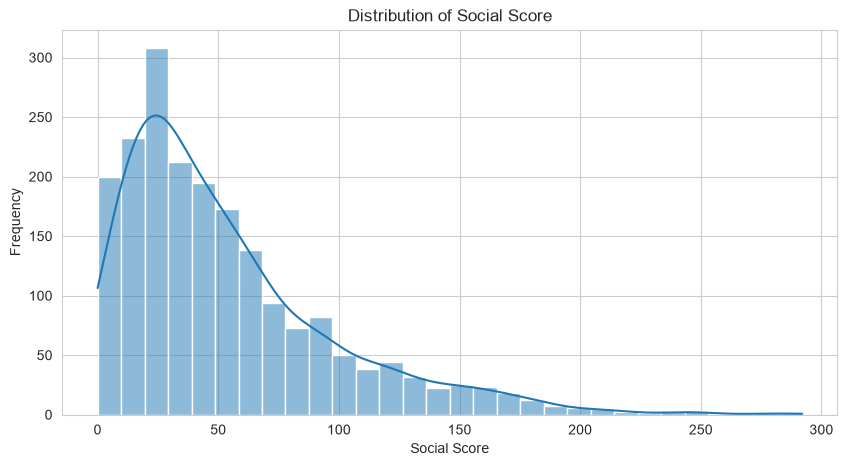

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="social_score",
    bins=30,
    kde=True
)

plt.title("Distribution of Social Score")
plt.xlabel("Social Score")
plt.ylabel("Frequency")

plt.show()

The distribution of `social_score` is positively skewed, with most players concentrated at lower to moderate levels of social activity and a progressively smaller number of highly social users.

The majority of observations fall below a score of approximately 75, while a long right tail extends toward substantially higher values, indicating the presence of a small group of highly interactive players.

This pattern aligns with the behavior typically observed in online communities, where a minority of users contribute disproportionately to social interactions.

From a segmentation perspective, the feature appears capable of distinguishing players with different levels of community participation and may be particularly useful for identifying socially engaged player profiles during clustering.

### <font color='green'>**4.3.3 Component Contribution Check**</font>

The social score is built by adding three variables measured on different scales. As was done for the engagement score, we verify how much each component contributes to the final score before using it for clustering.

Two indicators are reviewed:

- **Standard deviation** of each component, which shows how much each variable can move the score.
- **Correlation with the score**, which shows how closely the score follows each variable.

In [7]:
social_components = [
    "Friend Invites Sent",
    "Friend Invites Received",
    "Guild Chat Messages"
]

pd.DataFrame({
    "std": df[social_components].std(),
    "corr_with_score": df[social_components].corrwith(df["social_score"])
}).round(3)

,std,corr_with_score
Friend Invites Sent,17.064,0.422
Friend Invites Received,23.881,0.595
Guild Chat Messages,31.195,0.748


The contribution check shows that the `social_score` is reasonably balanced, with a moderate difference between its components:

- The standard deviations of the three components are of the same order of magnitude (`Friend Invites Sent`: 17.1, `Friend Invites Received`: 23.9, `Guild Chat Messages`: 31.2).
- The correlation between the score and each component ranges from 0.42 to 0.75, so no single variable explains the score on its own.

`Guild Chat Messages` contributes the most to the score (correlation of 0.75, with a standard deviation about 1.8 times that of `Friend Invites Sent`), but the imbalance is far smaller than the one found in the original engagement score, where `Time Played` reached a correlation of 1.000. For this reason, the `social_score` does not need to be rebuilt, and the simple sum is kept for interpretability.

**Limitation:** the social dimension therefore reflects chat activity somewhat more than friend invitations.

## <font color='green'>🟢 **4.4 Engagement Features**</font>

In this section, we create a feature designed to summarize overall player engagement.

Player engagement is a multidimensional concept that cannot be fully captured by a single variable. To better represent this behavior, we combine progression, activity, and login frequency metrics into a unified engagement score.

This feature is expected to play an important role in the segmentation process, as it captures several aspects of player commitment and interaction with the game.

### <font color='green'>**4.4.1 Engagement Feature Components**</font>

To represent player engagement, we combine progression, activity, and login frequency metrics into a single feature.

The engagement score is based on:

- Level
- Time Played
- Avg Daily Login

These variables collectively capture different dimensions of player commitment and participation within the game.

In [8]:
df["engagement_score"] = (
    df["Level"]
    + df["Time Played"]
    + df["Avg Daily Login"]
)

The `engagement_score` feature combines progression, activity, and login frequency into a single metric designed to represent overall player engagement.

By aggregating multiple behavioral dimensions, the feature aims to provide a more holistic representation of player commitment than any individual variable alone.

At this stage, the score serves as an initial engagement indicator. Its balance is assessed in the following sections.

### <font color='green'>**4.4.2 Initial Engagement Score Assessment**</font>

Before incorporating the engagement score into the analytical dataset, we review its statistical properties to verify that the feature captures meaningful variation across players.

This assessment also helps identify potential limitations that may need to be addressed during later preprocessing stages.

In [9]:
df["engagement_score"].describe()

count     2000.000000
mean     12618.144000
std      21419.595987
min        811.000000
25%        889.750000
50%       2392.500000
75%      12580.000000
max      95480.000000
Name: engagement_score, dtype: float64

The engagement score exhibits substantial variability across players, reflecting large differences in overall activity and progression levels.

However, the scale of the feature is heavily influenced by `Time Played`, whose values are considerably larger than those of `Level` and `Avg Daily Login`.

As a result, the current version of the engagement score primarily reflects playtime rather than an equal combination of all engagement-related dimensions.

The next sections quantify this imbalance and correct it so that each component contributes on an equal footing.

### <font color='green'>**4.4.3 Component Contribution Diagnosis**</font>

The engagement score is built by summing three variables measured on very different scales. Before using it for clustering, we verify how much each component actually contributes to the final score.

Two indicators are reviewed:

- **Standard deviation** of each component, which shows how much each variable can move the score.
- **Correlation with the score**, which shows how closely the score follows each variable.

In [10]:
components = ["Level", "Time Played", "Avg Daily Login"]

contribution = pd.DataFrame({
    "std": df[components].std(),
    "corr_with_score": df[components].corrwith(df["engagement_score"])
}).round(3)

contribution

,std,corr_with_score
Level,183.885,-0.034
Time Played,21426.372,1.000
Avg Daily Login,8.924,0.021


The diagnosis confirms that the current `engagement_score` is not a balanced composite.

- `Time Played` has a standard deviation of **21,426**, compared to **184** for `Level` and **8.9** for `Avg Daily Login`.
- The correlation between the score and `Time Played` is **1.000**, while it is only **-0.034** for `Level` and **0.021** for `Avg Daily Login`.

In practice, the score is `Time Played` under a different name. `Level` and `Avg Daily Login` have no real influence on it. Using it as it is would make any "highly engaged" segment simply a "high playtime" segment.

The next step is to rebuild the score so that each component contributes on an equal footing.

### <font color='green'>**4.4.4 Balanced Engagement Score**</font>

To correct the imbalance, each component is standardized (mean 0, standard deviation 1) before being combined. The balanced score is the average of the three standardized components, so no variable dominates because of its scale.

The new score is stored as `engagement_score_balanced`, and its correlation with each component is reviewed to verify the correction.

In [11]:
components = ["Level", "Time Played", "Avg Daily Login"]

engagement_scaled = pd.DataFrame(
    StandardScaler().fit_transform(df[components]),
    columns=components,
    index=df.index
)

df["engagement_score_balanced"] = engagement_scaled.mean(axis=1)

df[components].corrwith(df["engagement_score_balanced"]).round(3).to_frame("corr_with_score")

,corr_with_score
Level,0.520
Time Played,0.588
Avg Daily Login,0.558


The correction was successful. After standardizing the components before combining them, the correlation between `engagement_score_balanced` and each component is similar:

- `Level`: **0.520**
- `Time Played`: **0.588**
- `Avg Daily Login`: **0.558**

Compared to the original score, where `Time Played` explained virtually everything (correlation of 1.000), the balanced version reflects progression, playtime, and login frequency on equal footing. This makes the score a more reliable representation of overall player engagement. However, the three components are only weakly related to each other (notebook 2, section 3.3.3), so the score should be read as a general activity index rather than a measure of a single behavioral trait.

### <font color='green'>**4.4.5 Distribution Comparison**</font>

We compare the distribution of the original and balanced engagement scores. The goal is to verify that the new score is no longer a copy of `Time Played`, and to check whether any skewness remains that could affect the clustering stage.

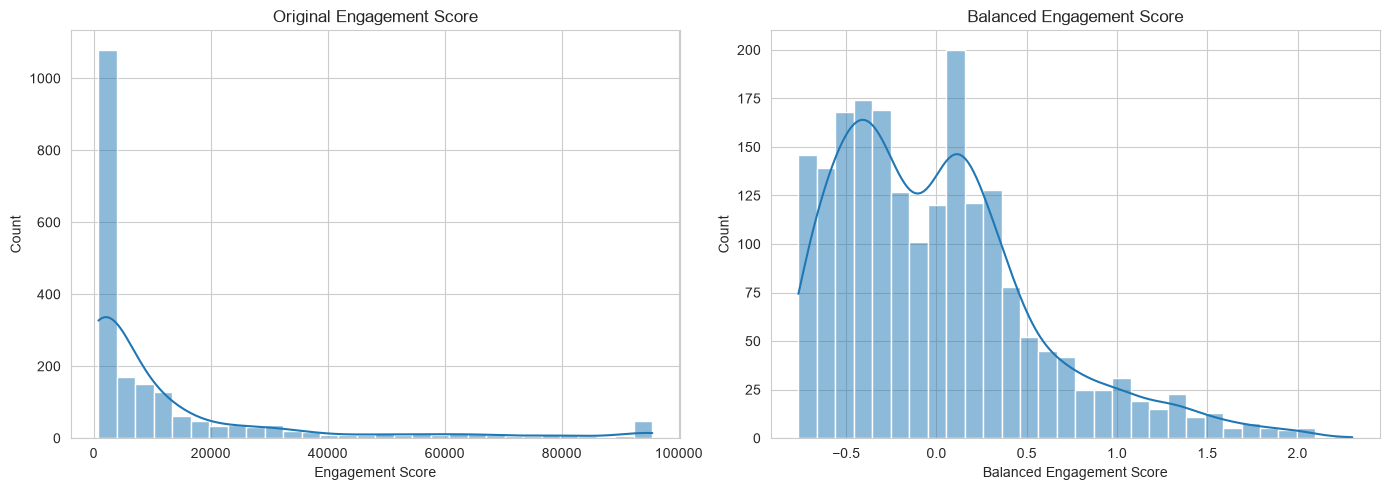

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="engagement_score",
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Original Engagement Score")
axes[0].set_xlabel("Engagement Score")

sns.histplot(
    data=df,
    x="engagement_score_balanced",
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Balanced Engagement Score")
axes[1].set_xlabel("Balanced Engagement Score")

plt.tight_layout()
plt.show()

The comparison confirms that the balanced score behaves very differently from the original one.

- The **original score** concentrates over 1,000 observations in its first bin and extends along a long tail up to 95,000, with an isolated bar at the upper end that reflects the ceiling of `Time Played`.
- The **balanced score** ranges from approximately -0.8 to 2.3, shows two concentration zones, and has a much milder right tail.

Some right skewness remains: after standardization, the highest values reach roughly 4 standard deviations above the mean. The tail is moderate and does not make the score unsuitable for clustering, but these high-value observations will be monitored in the segmentation stage, since they may form small, distinct groups. For this reason, `engagement_score_balanced` replaces the original score from this point on.

The balanced score has a standard deviation of about 0.55, so its maximum of roughly 2.3 corresponds to about 4 standard deviations above the mean.

### <font color='green'>**4.4.6 Engagement Features Summary**</font>

The engagement feature engineering process followed three steps:

1. An initial `engagement_score` was created by summing `Level`, `Time Played`, and `Avg Daily Login`.
2. A diagnosis showed that the score was dominated by `Time Played` (correlation of 1.000 with the score), while `Level` and `Avg Daily Login` had virtually no influence.
3. A balanced version, `engagement_score_balanced`, was built by standardizing each component before averaging them. All three components now correlate similarly with the score (0.52 to 0.59).

From this point on, only `engagement_score_balanced` is used. The original `engagement_score` remains in the notebook as documentation of the problem and its correction.

## <font color='green'>🟢 **4.5 Feature Selection**</font>

Before preparing the final analytical dataset, we review the engineered features and decide which ones will be used to build the segments.

The objective is to retain variables that capture meaningful aspects of player behavior while avoiding redundancy between them, since overlapping features would give some behavioral dimensions more weight than others in distance-based algorithms such as K-Means.

### <font color='green'>**4.5.1 Monetization Redundancy Check**</font>

The features under consideration are `engagement_score_balanced`, `social_score`, `Purchase Amount`, and `is_payer`.

Two of them describe monetization. Since `is_payer` is derived directly from `Purchase Amount` (it equals 1 whenever the amount is greater than zero), they may carry overlapping information.

If this overlap is high, monetization would receive double weight in the distance calculations used by K-Means. We measure the correlation between the candidate features to quantify it.

In [13]:
redundancy_check = df[
    ["engagement_score_balanced", "social_score", "Purchase Amount", "is_payer"]
].corr().round(2)

redundancy_check

,engagement_score_balanced,social_score,Purchase Amount,is_payer
engagement_score_balanced,1.00,0.12,0.01,-0.03
social_score,0.12,1.00,0.06,0.01
Purchase Amount,0.01,0.06,1.00,0.48
is_payer,-0.03,0.01,0.48,1.00


The correlation between `Purchase Amount` and `is_payer` is **0.48**, while all other pairs of features remain below **0.12** in absolute value.

Although a correlation of 0.48 is moderate, it understates the real overlap. `is_payer` is a deterministic function of `Purchase Amount` (it equals 0 when the amount is zero and 1 otherwise), so every piece of information it contains is already present in `Purchase Amount`. Because `Purchase Amount` contains many zeros, Pearson correlation cannot capture this structural dependency fully.

As a result, monetization would occupy two of the four dimensions used by K-Means, giving it double weight in the distance calculations, while engagement and social activity would have only one dimension each.

### <font color='green'>**4.5.2 Monetization Feature Decision**</font>

Based on the redundancy check, `is_payer` is removed from the set of segmentation features. `Purchase Amount` is retained because it already identifies non-paying players (value of zero) and additionally preserves the magnitude of spending, which `is_payer` discards.

The `is_payer` variable remains available in the dataset and will be used later to describe the resulting segments, rather than to build them.

The final segmentation features represent three behavioral dimensions with one feature each: engagement, social activity, and monetization.

### <font color='green'>**4.5.3 Final Segmentation Features**</font>

Based on the previous decision, the final set of features used to build the segments is defined below.

In [14]:
candidate_features = [
    "engagement_score_balanced",
    "social_score",
    "Purchase Amount"
]

The final set of candidate features was selected to represent the three main behavioral dimensions identified throughout the project:

- **Engagement** (`engagement_score_balanced`)
- **Social Activity** (`social_score`)
- **Monetization Value** (`Purchase Amount`)

This selection prioritizes interpretability while minimizing redundancy between highly related variables.

By using engineered features that summarize multiple behavioral indicators, the final segmentation process can focus on broader player characteristics rather than individual gameplay metrics.

### <font color='green'>**4.5.4 Variables Excluded from the Segmentation**</font>

Several original variables are not used to build the segments: `Attempts`, `Booster Used`, `Level Completion Time`, `Lives from Ads`, and `OS Version`.

The segmentation was designed around three interpretable behavioral dimensions (engagement, social activity, and monetization). `OS Version` is a technical attribute rather than a behavior. The remaining variables describe gameplay intensity and ad-based interaction and were left out to keep the feature set compact and interpretable.

**Limitation:** `Lives from Ads` reflects ad-driven monetization, which is not captured because monetization is measured only through purchases. `Attempts` was listed as a variable of interest in hypothesis 3 but is not part of the final feature set.

## <font color='green'>🟢 **4.6 Analytical Dataset Creation**</font>

In this section, we create the analytical dataset that will be used for player segmentation.

The dataset contains the final set of selected features representing engagement, social behavior, and monetization characteristics.

This structure will serve as the foundation for all clustering analyses performed in the next notebook.

In [15]:
segmentation_df = df[candidate_features].copy()

segmentation_df.head()

,engagement_score_balanced,social_score,Purchase Amount
0,0.648087,15,20.30
1,-0.234236,32,46.55
2,0.354433,13,23.49
3,0.296978,82,0.71
4,-0.382655,22,4.41


The analytical dataset consolidates the three behavioral dimensions identified throughout the project:

- Engagement (`engagement_score_balanced`)
- Social Activity (`social_score`)
- Monetization Value (`Purchase Amount`)

By combining engineered features with the spending amount, the dataset provides a compact and interpretable representation of player behavior.

This reduced feature set is expected to improve the interpretability of the segmentation process while retaining the most relevant behavioral information discovered during the exploratory analysis.

## <font color='green'>🟢 **4.7 Feature Scaling**</font>

Before applying clustering algorithms, it is necessary to standardize the numerical features.

Clustering methods such as K-Means are highly sensitive to variable scale. Without scaling, features with larger numerical ranges can dominate the distance calculations and disproportionately influence the resulting clusters.

To ensure that all variables contribute fairly to the segmentation process, we apply standardization using the StandardScaler technique.

### <font color='green'>**4.7.1 Standardization of Features**</font>

In this section, we standardize the selected features so that they share a comparable scale.

This transformation centers each variable around zero and scales it according to its standard deviation, reducing the impact of large differences in measurement units.

In [16]:
scaler = StandardScaler()

segmentation_scaled = scaler.fit_transform(
    segmentation_df
)

segmentation_scaled = pd.DataFrame(
    segmentation_scaled,
    columns=segmentation_df.columns
)

segmentation_scaled.head()

,engagement_score_balanced,social_score,Purchase Amount
0,1.166929,-0.860152,0.241280
1,-0.421760,-0.480157,1.355506
2,0.638184,-0.904858,0.376685
3,0.534731,0.637475,-0.590252
4,-0.689000,-0.703684,-0.433199


The standardization process was successfully applied to all selected features.

As a result, engagement, social activity, and monetization variables now operate on comparable scales, reducing the risk of any single feature disproportionately influencing the clustering process.

The standardized dataset is therefore better suited for distance-based algorithms such as K-Means and provides a more balanced representation of player behavior.

### <font color='green'>**4.7.2 Scaling Verification**</font>

We verify that the standardization was applied correctly: each feature should have a mean of approximately 0 and a standard deviation of approximately 1.

In [17]:
segmentation_scaled.describe().round(2)

,engagement_score_balanced,social_score,Purchase Amount
count,2000.00,2000.00,2000.00
mean,0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.38,-1.20,-0.62
25%,-0.77,-0.70,-0.62
50%,-0.13,-0.28,-0.39
75%,0.51,0.41,0.26
max,4.15,5.33,3.62


The verification confirms that, after removing `is_payer`, the three remaining features are correctly standardized, each with a mean of approximately 0 and a standard deviation of 1.00.

The segmentation dataset now represents three behavioral dimensions with one feature each: engagement (`engagement_score_balanced`), social activity (`social_score`), and monetization (`Purchase Amount`).

## <font color='green'>🟢 **4.8 Feature Engineering Summary**</font>

This notebook focused on transforming raw player information into a structured analytical dataset suitable for segmentation.

Key accomplishments include:

- Creation of the `is_payer` feature to identify monetized players. It is kept to describe the segments later, not to build them.
- Development of the `social_score` feature to summarize social behavior.
- Diagnosis of the original `engagement_score`, which turned out to be dominated by `Time Played`, and construction of `engagement_score_balanced`, where each component contributes on an equal footing.
- Detection of redundancy between `Purchase Amount` and `is_payer`, and removal of `is_payer` from the segmentation features to avoid giving monetization double weight.
- Creation of the analytical dataset with three features, one per behavioral dimension: engagement, social activity, and monetization.
- Standardization of the selected features, verified through summary statistics.

The resulting dataset provides a compact and interpretable representation of player behavior across engagement, social activity, and monetization dimensions.

The next notebook will focus on player segmentation using clustering techniques to identify meaningful player groups and generate actionable business insights.

## <font color='green'>🟢 **4.9 Exporting the Analytical Datasets**</font>

To maintain a modular and reproducible workflow, two files are exported for the clustering stage:

- `segmentation_dataset.csv`: the standardized features used to build the segments.
- `profiling_dataset.csv`: the same records in their original units, with a `record_id` and additional variables (including `is_payer`, the engagement components, and categorical attributes) used to describe the resulting segments.

Both files keep the same row order, so the segment labels assigned in the next notebook can be attached to the profiling dataset. The variables in the profiling dataset are **not** used to build the segments; they only help interpret them.

In [18]:
profile_columns = [
    "engagement_score_balanced",
    "social_score",
    "Purchase Amount",
    "is_payer",
    "Level",
    "Time Played",
    "Avg Daily Login",
    "Device Type",
    "Facebook Connect Status",
    "Social Engagement through Facebook",
    "Specific Action Usage"
]

profiling_df = df[profile_columns].copy()
profiling_df.insert(0, "record_id", df.index)

assert len(profiling_df) == len(segmentation_scaled)
assert profiling_df.index.equals(segmentation_scaled.index)

PROCESSED_PATH = Path("../data/processed")
PROCESSED_PATH.mkdir(parents=True, exist_ok=True)

segmentation_scaled.to_csv(
    PROCESSED_PATH / "segmentation_dataset.csv",
    index=False
)

profiling_df.to_csv(
    PROCESSED_PATH / "profiling_dataset.csv",
    index=False
)

print("✅ Analytical datasets exported successfully.")

✅ Analytical datasets exported successfully.


In [19]:
print("Segmentation dataset:", segmentation_scaled.shape)
print("Profiling dataset:   ", profiling_df.shape)

profiling_df.head()

Segmentation dataset: (2000, 3)
Profiling dataset:    (2000, 12)


,record_id,engagement_score_balanced,social_score,Purchase Amount,is_payer,Level,Time Played,Avg Daily Login,Device Type,Facebook Connect Status,Social Engagement through Facebook,Specific Action Usage
0,0,0.648087,15,20.30,1,480,800,16,Samsung Galaxy,Yes,low,Fish Usage
1,1,-0.234236,32,46.55,1,60,17048,6,Android,No,low,Striped Candy Swipe
2,2,0.354433,13,23.49,1,95,7581,24,iPhone,Yes,low,Fish Usage
3,3,0.296978,82,0.71,1,293,4828,14,iPad,No,low,Extra Time Boost
4,4,-0.382655,22,4.41,1,10,1331,11,iPad,Yes,low,Special Candy Swap
